# 05 — Experimento 4: PLN

Classificação de sintomas (TF-IDF + LR vs. LinearSVC calibrado) com validação cruzada 5-fold e **reconhecimento de intenção da pergunta** do usuário.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
from src.nlp.symptom_classifier import SymptomClassifier
from src.nlp.question_intent import QuestionIntentClassifier, split_user_message
for algo in ('logistic_regression', 'svm'):
    m = SymptomClassifier(algorithm=algo).train_from_csv(evaluate_cv=True)
    print(f'{algo:20s} acc={m.accuracy:.4f} F1={m.f1_macro:.4f} (N={m.num_samples}, 5-fold)')
print('Intenção da pergunta (CV 5-fold):', QuestionIntentClassifier().evaluate_cv())

logistic_regression  acc=0.8056 F1=0.8058 (N=180, 5-fold)


svm                  acc=0.8111 F1=0.8116 (N=180, 5-fold)
Intenção da pergunta (CV 5-fold): {'n': 150, 'accuracy': 0.8467, 'f1_macro': 0.8467}


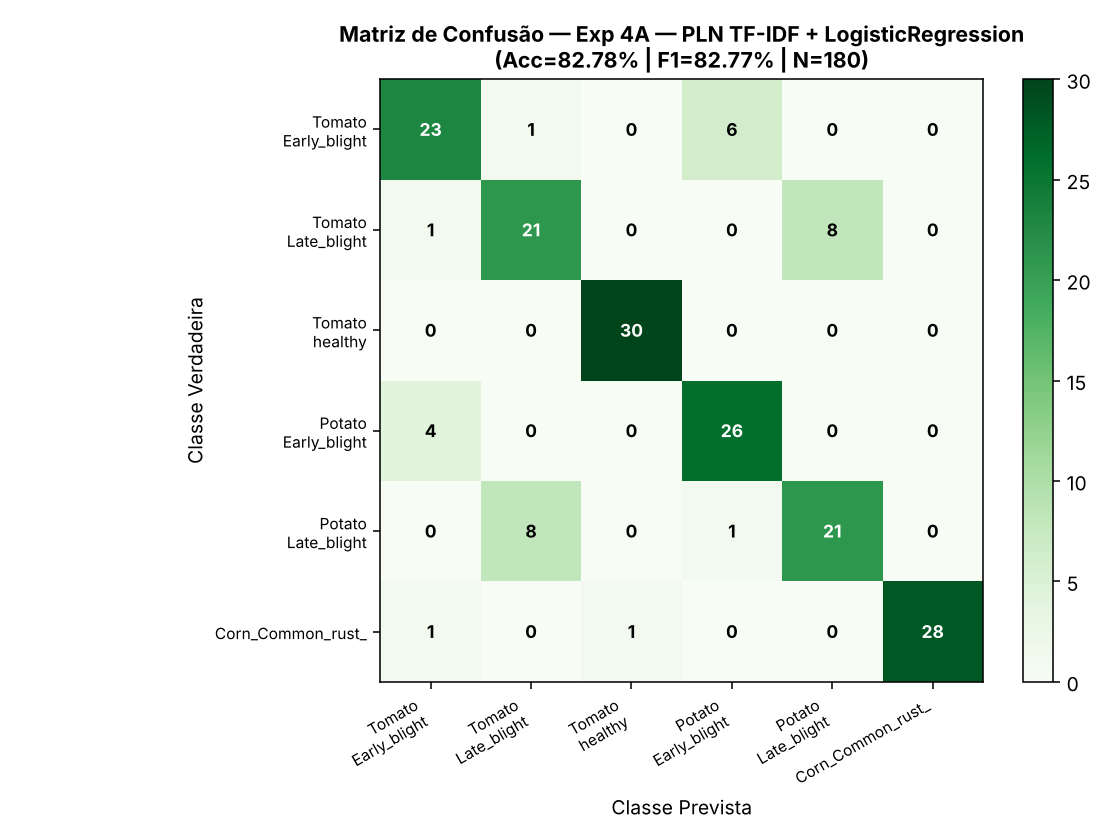

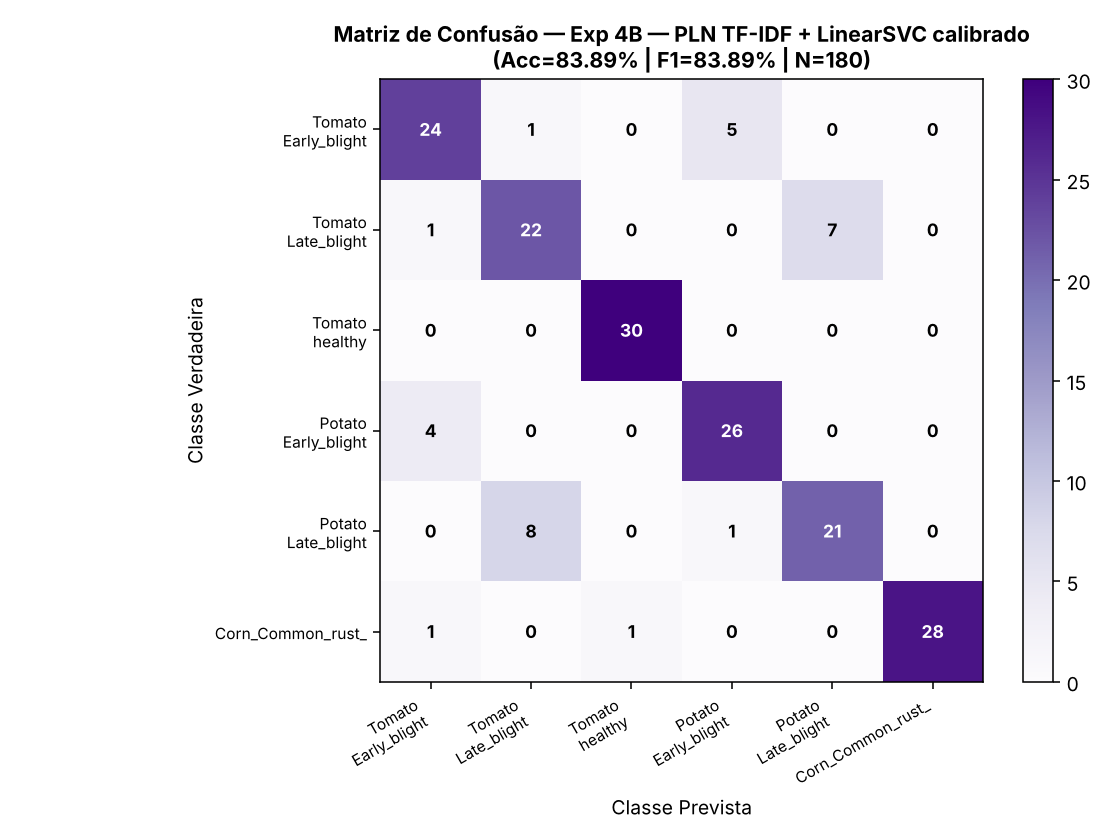

In [3]:
show('confusion_matrices/exp4_nlp_lr_cm.png'); show('confusion_matrices/exp4_nlp_svm_cm.png')

In [4]:
clf = SymptomClassifier(); clf.train_from_csv(evaluate_cv=False); qi = QuestionIntentClassifier().train_from_csv()
for msg in ['Folhas de tomateiro com anéis concêntricos tipo alvo e halo amarelo. Como tratar?',
            'Minha batata ficou com a folha preta e molhada depois da chuva, tem mofo branco. É grave?',
            'Folha de tomate verde e limpa, sem manchas. Está saudável?']:
    parts = split_user_message(msg); out = clf.predict(parts.symptom_text); intent = qi.predict(parts.question)
    print(msg); print('  ->', out['predicted_class'], f"({out['confidence']:.0%})", '| sintomas:', out['metadata']['extracted_symptoms'], '| intenção:', intent[0])

Folhas de tomateiro com anéis concêntricos tipo alvo e halo amarelo. Como tratar?
  -> Tomato___Early_blight (98%) | sintomas: ['aneis_concentricos', 'halo_amarelado'] | intenção: treatment
Minha batata ficou com a folha preta e molhada depois da chuva, tem mofo branco. É grave?
  -> Potato___Late_blight (90%) | sintomas: ['mofo_esbranquicado'] | intenção: severity
Folha de tomate verde e limpa, sem manchas. Está saudável?
  -> Tomato___healthy (98%) | sintomas: ['folha_saudavel'] | intenção: confirm


**Limitação:** o corpus foi redigido pela equipe (180 textos); textos sem a cultura citada são ambíguos entre tomate e batata — é aí que a imagem complementa o texto (Exp 5).